<a href="https://www.kaggle.com/code/makrrc/0-78676-v12-spaceship-titanic?scriptVersionId=123126288" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [ ]:
##Spaceship Titanic'

In [226]:
"""
Import from libraries that will be used in the project

"""

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# machine learning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import Perceptron
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


from sklearn import *

print('Carregou as bibliotecas...')

Carregou as bibliotecas...


In [227]:
##Biblioteca de tempo e paralelização de tarefas
import time
from joblib import Parallel, delayed

In [228]:
##model validation

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import accuracy_score

print('Loaded the libraries...')

Loaded the libraries...


In [229]:
train_df = pd.read_csv("/kaggle/input/spaceship-titanic/train.csv")
print("Database loaded")

Database loaded


In [230]:
test_df = pd.read_csv("/kaggle/input/spaceship-titanic/test.csv")
print("Test database loaded")

Test database loaded


In [231]:
PassengerId = pd.read_csv("/kaggle/input/spaceship-titanic/test.csv")['PassengerId']
##test_df
PassengerId

0       0013_01
1       0018_01
2       0019_01
3       0021_01
4       0023_01
         ...   
4272    9266_02
4273    9269_01
4274    9271_01
4275    9273_01
4276    9277_01
Name: PassengerId, Length: 4277, dtype: object

In [232]:
combine = [train_df, test_df]
print("Training and test database are loaded")

Training and test database are loaded


In [233]:
"After", train_df.shape, test_df.shape, combine[0].shape, combine[1].shape

('After', (8693, 14), (4277, 13), (8693, 14), (4277, 13))

In [234]:
##Check the columns

train_df.columns.values

array(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination',
       'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa',
       'VRDeck', 'Name', 'Transported'], dtype=object)

In [235]:
##Check the first records

train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [236]:
## Correlation of columns to analyse

train_df.corr()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported
Age,1.000000,0.068723,0.130421,0.033133,0.123970,0.101007,-0.075026
RoomService,0.068723,1.000000,-0.015889,0.054480,0.010080,-0.019581,-0.244611
FoodCourt,0.130421,-0.015889,1.000000,-0.014228,0.221891,0.227995,0.046566
ShoppingMall,0.033133,0.054480,-0.014228,1.000000,0.013879,-0.007322,0.010141
Spa,0.123970,0.010080,0.221891,0.013879,1.000000,0.153821,-0.221131
VRDeck,0.101007,-0.019581,0.227995,-0.007322,0.153821,1.000000,-0.207075
Transported,-0.075026,-0.244611,0.046566,0.010141,-0.221131,-0.207075,1.000000


<AxesSubplot:>

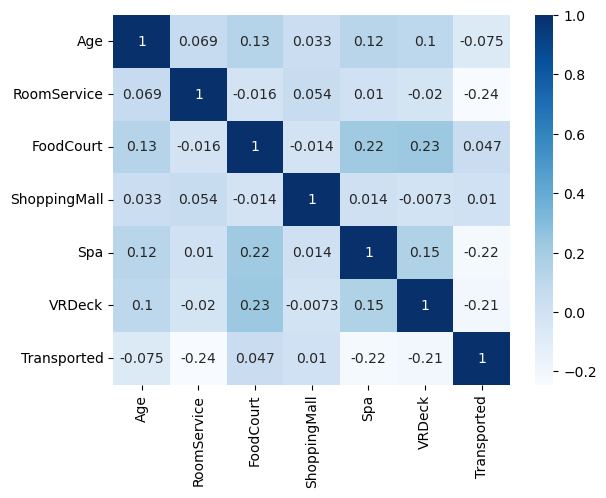

In [237]:
##Heatmap of columns correlation to analyse

sns.heatmap(train_df.corr(),cmap="Blues",annot=True)

In [238]:
##Total records

print("Total de: ",train_df['PassengerId'].count(), " registros")

Total de:  8693  registros


In [239]:
## Check for nulls in train_df base by column

train_df.isnull().sum().sort_values(ascending=False)

CryoSleep       217
ShoppingMall    208
VIP             203
HomePlanet      201
Name            200
Cabin           199
VRDeck          188
FoodCourt       183
Spa             183
Destination     182
RoomService     181
Age             179
PassengerId       0
Transported       0
dtype: int64

In [240]:
## Brings statistical information about the base

train_df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [241]:
## Median values by columns

train_df.median()[1:]
print('_'*40)
test_df.median()[1:]

________________________________________


/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:3: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  This is separate from the ipykernel package so we can avoid doing imports until
/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:5: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  """


CryoSleep        0.0
Age             26.0
VIP              0.0
RoomService      0.0
FoodCourt        0.0
ShoppingMall     0.0
Spa              0.0
VRDeck           0.0
dtype: float64

In [242]:
## Info values ( Column, Non-Null, Count, Dtype ) by columns

train_df.info()
print('_'*40)
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB
________________________________________
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 13 colu

In [243]:
## Ungroup family from code and add to dataframe to know how many families and correlate with survivors
## train_df

train_df['family_group'] = train_df['PassengerId'].str.split("_", n = 1, expand = True)[0]

In [244]:
## Ungroup family from code and add to dataframe to know how many families and correlate with survivors
## train_df

test_df['family_group'] = test_df['PassengerId'].str.split("_", n = 1, expand = True)[0]

In [245]:
## Join the modified bases in combine

combine = [train_df, test_df]
combine

[     PassengerId HomePlanet CryoSleep     Cabin    Destination   Age    VIP  \
 0        0001_01     Europa     False     B/0/P    TRAPPIST-1e  39.0  False   
 1        0002_01      Earth     False     F/0/S    TRAPPIST-1e  24.0  False   
 2        0003_01     Europa     False     A/0/S    TRAPPIST-1e  58.0   True   
 3        0003_02     Europa     False     A/0/S    TRAPPIST-1e  33.0  False   
 4        0004_01      Earth     False     F/1/S    TRAPPIST-1e  16.0  False   
 ...          ...        ...       ...       ...            ...   ...    ...   
 8688     9276_01     Europa     False    A/98/P    55 Cancri e  41.0   True   
 8689     9278_01      Earth      True  G/1499/S  PSO J318.5-22  18.0  False   
 8690     9279_01      Earth     False  G/1500/S    TRAPPIST-1e  26.0  False   
 8691     9280_01     Europa     False   E/608/S    55 Cancri e  32.0  False   
 8692     9280_02     Europa     False   E/608/S    TRAPPIST-1e  44.0  False   
 
       RoomService  FoodCourt  Shoppin

In [246]:
##Total de grupos com mais de um status para Transported

train_df.groupby('family_group').agg({'Transported': 'count'}).reset_index().query('Transported > 2')

,family_group,Transported
7,0008,3
16,0020,6
23,0031,3
31,0044,3
37,0056,3
...,...,...
6170,9205,3
6177,9220,3
6183,9227,5
6185,9231,3


In [247]:
##Constatamos que criança de 12 anos abaixo não tem gasto. Qualquer Criança que estejam sem este dados poderá ser imputado 0 em todos os gastos

train_df[(train_df['Age'] < 12) & (train_df['RoomService'] != 0) & (train_df['FoodCourt'] != 0) & (train_df['ShoppingMall'] !=0 ) & (train_df['Spa'] != 0) & (train_df['VRDeck'] != 0)]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group


In [248]:
##Agora vamos inputar à todas as crianças nan e nulas valor 0 em todos os serviços para a train


train_df.loc[(train_df['Age'] < 12), ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']] = 0
train_df.loc[(train_df['Age'] < 18), ['VIP']] = False

In [249]:
##Agora vamos inputar à todas as crianças nan e nulas valor 0 em todos os serviços para a test


test_df.loc[(test_df['Age'] < 12), ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']] = 0
test_df.loc[(test_df['Age'] < 18), ['VIP']] = False

In [250]:
##Constatamos que Todos os registros da coluna Vip com idade até 17 anos foram preenchidas.
train_df[(train_df['Age'] < 18) & (train_df['VIP'] == True)]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group


In [251]:
##Constatamos que Todos os registros de colunas monetárias para crianças até 12 anos foram imputados 0.

train_df[(train_df['Age'] < 12) & (train_df['Spa'].isnull())]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group


In [252]:
## Notamos que há uma grande amostra de pessoas HomePlanet Europa estava em Criosleep. Testamos a condição contrária
train_df[(train_df['HomePlanet'] != 'Europa') & (train_df['CryoSleep'] == False)]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,0002
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,0004
5,0005_01,Earth,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,0.0,Sandie Hinetthews,True,0005
6,0006_01,Earth,False,F/2/S,TRAPPIST-1e,26.0,False,42.0,1539.0,3.0,0.0,0.0,Billex Jacostaffey,True,0006
8,0007_01,Earth,False,F/3/S,TRAPPIST-1e,35.0,False,0.0,785.0,17.0,216.0,0.0,Andona Beston,True,0007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8666,9248_01,NaN,False,F/1792/S,55 Cancri e,38.0,NaN,28.0,1208.0,973.0,207.0,0.0,Gian Perle,True,9248
8674,9257_01,NaN,False,F/1892/P,TRAPPIST-1e,13.0,False,39.0,0.0,1085.0,24.0,0.0,Ties Apple,False,9257
8682,9272_01,Earth,False,G/1507/P,TRAPPIST-1e,26.0,False,240.0,242.0,510.0,0.0,0.0,Ireene Simson,True,9272
8683,9272_02,Earth,False,F/1894/P,TRAPPIST-1e,21.0,False,86.0,3.0,149.0,208.0,329.0,Gordo Simson,False,9272


In [253]:
##Consultamos a faixa de idade de pessoas Por Homeplanet e Vip. E descobrimos que só tem Vip da faixa de 18 à 73 anos.

np.sort(train_df[(train_df['HomePlanet'] == 'Mars') & (train_df['VIP'] == True)]['Age'].unique())

array([18., 19., 20., 23., 25., 26., 27., 28., 29., 30., 31., 32., 33.,
       34., 35., 37., 38., 40., 41., 43., 45., 48., 50., 51., 54., 56.,
       57., 60., 61., 68., 71., nan])

In [254]:
##Consultamos a faixa de idade de pessoas Por Homeplanet e Vip. E descobrimos que só tem Vip da faixa de 18 à 73 anos.

np.sort(test_df[(test_df['HomePlanet'] == 'Mars') & (test_df['VIP'] == True)]['Age'].unique())

array([18., 22., 25., 26., 29., 32., 33., 34., 36., 39., 43., 44., 45.,
       46., 48., 51., 55.])

In [255]:
train_df[['family_group','PassengerId']].groupby('family_group')

In [256]:
test_df[['family_group','PassengerId']].groupby('family_group')

In [257]:
##train_df.isna().sum()
test_df.isna().sum()

PassengerId       0
HomePlanet       87
CryoSleep        93
Cabin           100
Destination      92
Age              91
VIP              84
RoomService      75
FoodCourt        98
ShoppingMall     93
Spa              93
VRDeck           69
Name             94
family_group      0
dtype: int64

In [258]:
train_df.groupby("family_group").count()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
family_group,,,,,,,,,,,,,,
0001,1,1,1,1,1,1,1,1,1,1,1,1,1,1
0002,1,1,1,1,1,1,1,1,1,1,1,1,1,1
0003,2,2,2,2,2,2,2,2,2,2,2,2,2,2
0004,1,1,1,1,1,1,1,1,1,1,1,1,1,1
0005,1,1,1,1,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9275,3,3,2,3,3,3,3,3,3,3,3,3,3,3
9276,1,1,1,1,1,1,1,1,1,1,1,1,1,1
9278,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [259]:
##Consultamos todas as famílias que tem, pelo menos, um membro em Criosleep e que haja mais de um membro.

family_group_test = test_df[train_df['CryoSleep'].isnull() & test_df.groupby('family_group')['family_group'].transform('size').gt(1)].sort_values('family_group')['family_group'].unique()
family_group_test

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  This is separate from the ipykernel package so we can avoid doing imports until


array(['0230', '0489', '0584', '0827', '0943', '1301', '1422', '1477',
       '1492', '1629', '2108', '2344', '2976', '3008', '3037', '3122',
       '3290', '3368', '3494', '4133', '4298', '4523', '5241', '5329',
       '5789', '6260', '6288', '6612', '6700', '6986', '7100', '7329',
       '7348', '7582', '8181', '8340', '8400', '8793', '8913'],
      dtype=object)

In [260]:
##Consultamos todas as famílias que tem, pelo menos, um membro em Criosleep e que haja mais de um membro.

family_group = train_df[train_df['CryoSleep'].isnull() & train_df.groupby('family_group')['family_group'].transform('size').gt(1)].sort_values('family_group')['family_group'].unique()
family_group

array(['0099', '0110', '0290', '0348', '0433', '0454', '0568', '0712',
       '0770', '0794', '1116', '1453', '1500', '1624', '1712', '1865',
       '1874', '1882', '2019', '2135', '2234', '2291', '2347', '2384',
       '2558', '2595', '2760', '2822', '3029', '3060', '3163', '3189',
       '3272', '3301', '3422', '3439', '3476', '3489', '3608', '3609',
       '3714', '3747', '3962', '4006', '4066', '4108', '4258', '4315',
       '4371', '4401', '4446', '4569', '4603', '4606', '4680', '4741',
       '4932', '4981', '5090', '5205', '5447', '5552', '5625', '5756',
       '5855', '5927', '6035', '6039', '6066', '6139', '6285', '6309',
       '6324', '6405', '6444', '6525', '6585', '6662', '6674', '6675',
       '6741', '6787', '6827', '6899', '7083', '7186', '7402', '7584',
       '7604', '7697', '7848', '7872', '7891', '7902', '8015', '8119',
       '8252', '8276', '8339', '8366', '8431', '8574', '8719', '8728',
       '8944', '9197', '9227', '9275'], dtype=object)

In [261]:
##Peguei um caso isolado para criar um filtro que pudesse pegar as linhas que seja igual à primeira linha family_group que esteja não nula

train_df[(train_df['family_group'] == '0099') & (train_df['Cabin'].notnull())][:1]['Cabin']

91    F/19/P
Name: Cabin, dtype: object

In [262]:
#Estou atribuindo ao dataset o valor filtrado pelo código da família à cabine do primeiro membro da família diferente de nulo para todos que estiverem nulos



def cabinByFamilyGroup(base_df, groups):
    inicial = time.time()
    for group in groups:
        cabin_notnull = base_df[(base_df['family_group'] == group) & (base_df['Cabin'].notnull())]
        if len(cabin_notnull) > 0:
            cabin_str = cabin_notnull.iloc[0]['Cabin']
            base_df.loc[(base_df['family_group'] == group ) & ( base_df['Cabin'].isnull() ), 'Cabin'] = cabin_str

    print(" inicial train: ",inicial," ,Final train",time.time()," Duração train: ",time.time() - inicial)       
            
            
#cabinByFamilyGroup(train_df)  
#cabinByFamilyGroup(test_df)  


In [263]:
def process_group_parallel(train_df, groups):
    cabin_notnull = train_df[(train_df['family_group'] == group) & (train_df['Cabin'].notnull())]
    if len(cabin_notnull) > 0:
        cabin_str = cabin_notnull.iloc[0]['Cabin']
        train_df.loc[ ( train_df['family_group'] == group & train_df['Cabin'].isnull() ), 'Cabin'] = cabin_str

def cabinByFamilyGroup_parallel(train_df, groups):
    inicial = time.time()
    #groups = train_df['family_group'].unique()
    Parallel(n_jobs=-1, backend='multiprocessing')(delayed(process_group_parallel)(train_df, groups) for group in groups)
    print(" inicial train: ",inicial," ,Final train",time.time()," Duração train: ",time.time() - inicial)

In [264]:
#inicial = time.time()
cabinByFamilyGroup(test_df, family_group_test) 
#print(" inicial: ",inicial," ,Final ",time.time()," Duração: ",time.time() - inicial)

 inicial train:  1679536872.0465577  ,Final train 1679536872.1588776  Duração train:  0.11232113838195801


In [265]:
test_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,family_group
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning,0013
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers,0018
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus,0019
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter,0021
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez,0023


In [266]:
#base = train_df.pop('Transported')
train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,0001
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,0002
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,0003
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,0003
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,0004


In [267]:
#inicial = time.time()
cabinByFamilyGroup(train_df, family_group)  
#print(" inicial: ",inicial," ,Final ",time.time()," Duração: ",time.time() - inicial)

 inicial train:  1679536872.2165048  ,Final train 1679536872.5936828  Duração train:  0.377178430557251


In [268]:
##Aqui confirmamos se está tudo correto. Deve retornar 0 linhas.
train_df[(train_df['family_group'] == '0110') & (train_df['Cabin'].isnull())]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group


In [269]:
train_df.groupby("family_group")['PassengerId'].count()

family_group
0001    1
0002    1
0003    2
0004    1
0005    1
       ..
9275    3
9276    1
9278    1
9279    1
9280    2
Name: PassengerId, Length: 6217, dtype: int64

In [270]:
train_df.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           188
Destination     182
Age             179
VIP             158
RoomService     162
FoodCourt       171
ShoppingMall    189
Spa             169
VRDeck          165
Name            200
Transported       0
family_group      0
dtype: int64

In [271]:
train_df[(train_df['Destination'] == 'TRAPPIST-1e') 
             & (train_df['RoomService'] == 0)
            & (train_df['FoodCourt'] == 0)
            & (train_df['ShoppingMall'] == 0)
            & (train_df['Spa'] == 0)
            & (train_df['VRDeck'] == 0)
            & (train_df['Transported'] == True)
        & (train_df['Transported'].isnull())]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group


In [272]:
train_df [(train_df['RoomService'] == 0)
            | (train_df['FoodCourt'] == 0)
            | (train_df['ShoppingMall'] == 0)
            | (train_df['Spa'] == 0)
            | (train_df['VRDeck'] == 0)]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,0001
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,0003
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,0003
5,0005_01,Earth,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,0.0,Sandie Hinetthews,True,0005
6,0006_01,Earth,False,F/2/S,TRAPPIST-1e,26.0,False,42.0,1539.0,3.0,0.0,0.0,Billex Jacostaffey,True,0006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,9276
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,9278
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,9279
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,9280


In [273]:
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'].isnull()), 'VRDeck'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'].isnull()) & (test_df['VRDeck'] == 0), 'Spa'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'].isnull()) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'ShoppingMall'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'].isnull()) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'FoodCourt'] = 0
test_df.loc [(test_df['RoomService'].isnull()) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'RoomService'] = 0

In [274]:
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'].isnull()), 'VRDeck'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'].isnull()) & (train_df['VRDeck'] == 0), 'Spa'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'].isnull()) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'ShoppingMall'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'].isnull()) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'FoodCourt'] = 0
train_df.loc [(train_df['RoomService'].isnull()) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'RoomService'] = 0

In [275]:
train_df[train_df['PassengerId'] == '0402_01']

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group
365,0402_01,NaN,True,D/15/S,55 Cancri e,32.0,True,0.0,0.0,0.0,0.0,0.0,Teron Sageng,True,0402


In [276]:
##train_df.loc [(train_df['VIP'] == True) & (train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0)]

In [277]:
train_df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           188
Destination     182
Age             179
VIP             158
RoomService     107
FoodCourt       108
ShoppingMall    108
Spa             117
VRDeck          109
Name            200
Transported       0
family_group      0
dtype: int64

In [278]:
train_df[(train_df['PassengerId']=='0006_02')]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,family_group
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,0.0,Candra Jacostaffey,True,0006


In [279]:
##
"""
train_df.loc[(train_df['Destination'] == 'TRAPPIST-1e') 
             & (train_df['RoomService'] == 0)
            & (train_df['FoodCourt'] == 0)
            & (train_df['ShoppingMall'] == 0)
            & (train_df['Spa'] == 0)
            & (train_df['VRDeck'] == 0)
            & (train_df['Transported'] == True)
            & (train_df['Destination'] == 'TRAPPIST-1e')]

"""

"\ntrain_df.loc[(train_df['Destination'] == 'TRAPPIST-1e') \n             & (train_df['RoomService'] == 0)\n            & (train_df['FoodCourt'] == 0)\n            & (train_df['ShoppingMall'] == 0)\n            & (train_df['Spa'] == 0)\n            & (train_df['VRDeck'] == 0)\n            & (train_df['Transported'] == True)\n            & (train_df['Destination'] == 'TRAPPIST-1e')]\n\n"

In [280]:
train_df['Destination'].unique()

array(['TRAPPIST-1e', 'PSO J318.5-22', '55 Cancri e', nan], dtype=object)

In [281]:
##Total de grupos familiares

np.count_nonzero(train_df['family_group'].unique().astype('int') )

6217

In [282]:
## Group the data by family group whether or not it was transported

##train_df[train_df[['family_group','Transported']].groupby(['family_group'], as_index=False).count().sort_values(by='family_group', ascending=True)['Transported'] > 2]

In [283]:
## Ungroup Cabin column to deck/num/side in train_df base

train_df['deck'] = train_df['Cabin'].str.split("/", n = 1, expand = True)[0]
train_df['num'] = train_df['Cabin'].str.split("/", n = 2, expand = True)[1]
train_df['side'] = train_df['Cabin'].str.split("/", n = 3, expand = True)[2]

In [284]:
## Ungroup Cabin column to deck/num/side in base test_df

test_df['deck'] = test_df['Cabin'].str.split("/", n = 1, expand = True)[0]
test_df['num'] = test_df['Cabin'].str.split("/", n = 2, expand = True)[1]
test_df['side'] = test_df['Cabin'].str.split("/", n = 3, expand = True)[2]

In [285]:
## Join the modified bases in combine

combine = [train_df, test_df]
combine

[     PassengerId HomePlanet CryoSleep     Cabin    Destination   Age    VIP  \
 0        0001_01     Europa     False     B/0/P    TRAPPIST-1e  39.0  False   
 1        0002_01      Earth     False     F/0/S    TRAPPIST-1e  24.0  False   
 2        0003_01     Europa     False     A/0/S    TRAPPIST-1e  58.0   True   
 3        0003_02     Europa     False     A/0/S    TRAPPIST-1e  33.0  False   
 4        0004_01      Earth     False     F/1/S    TRAPPIST-1e  16.0  False   
 ...          ...        ...       ...       ...            ...   ...    ...   
 8688     9276_01     Europa     False    A/98/P    55 Cancri e  41.0   True   
 8689     9278_01      Earth      True  G/1499/S  PSO J318.5-22  18.0  False   
 8690     9279_01      Earth     False  G/1500/S    TRAPPIST-1e  26.0  False   
 8691     9280_01     Europa     False   E/608/S    55 Cancri e  32.0  False   
 8692     9280_02     Europa     False   E/608/S    TRAPPIST-1e  44.0  False   
 
       RoomService  FoodCourt  Shoppin

In [286]:
##Comparar origem e destino (earth)
earth_trappist = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
earth_55cancri_e = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
earth_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

In [287]:
##Comparar origem e destino (Europa)
europa_trappist = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
europa_55cancri_e = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
europa_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

In [288]:
##Comparar origem e destino (Europa)
mars_trappist = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
mars_55cancri_e = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
mars_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

In [289]:
##Aqui busquei relacionar HomePlanet com Destination 
##para ter a contagem para cada destino e verificar 
##se há correlação com a coluna alvo Transported
##Conclusão: Não achei correlação.

home_planet_destination = dict()
home_planet_destination["earth_trappist"] = (earth_trappist)
home_planet_destination["earth_55cancri_e"] = (earth_55cancri_e)
home_planet_destination["earth_pso_j318_22"] = (earth_pso_j318_22)
home_planet_destination["europa_trappist"] = (europa_trappist)
home_planet_destination["europa_55cancri_e"] = (europa_55cancri_e)
home_planet_destination["europa_pso_j318_22"] = (europa_pso_j318_22)
home_planet_destination["mars_trappist"] = (mars_trappist)
home_planet_destination["mars_55cancri_e"] = (mars_55cancri_e)
home_planet_destination["mars_pso_j318_22"] = (mars_pso_j318_22)   

home_planet_destination

{'earth_trappist': 3101,
 'earth_55cancri_e': 690,
 'earth_pso_j318_22': 712,
 'europa_trappist': 1189,
 'europa_55cancri_e': 886,
 'europa_pso_j318_22': 19,
 'mars_trappist': 1475,
 'mars_55cancri_e': 193,
 'mars_pso_j318_22': 49}

In [290]:
train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "55 Cancri e") & (train_df["Transported"] == False) ]["PassengerId"].count()

75

In [291]:
##Consulta deck, side,num por meio do deck
deck_num_side = train_df[['deck','side','num']][train_df[['deck','num','side']]["deck"] == "G"].sort_values(by=['deck','side','num'])
display(deck_num_side.drop_duplicates())

,deck,side,num
19,G,P,0
40,G,P,1
5835,G,P,1000
5839,G,P,1001
5843,G,P,1002
...,...,...,...
5792,G,S,994
5812,G,S,995
5820,G,S,996
5824,G,S,998


In [292]:
"""
print("Passageiros total:",train_df[['deck','PassengerId']].groupby("deck").count())
print("Passageiros transportados: ",train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count())
print("Percentual de passageiros transportados por deck: ",train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count() * 100
/ train_df[['deck','PassengerId']].groupby("deck").count(), "%" )


tabularTransportadosPorDeck = pd.Dataframe({"Percentual de passageiros transportados por deck: ":train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count() * 100
/ train_df[['deck','PassengerId']].groupby("deck").count()})
"""


'\nprint("Passageiros total:",train_df[[\'deck\',\'PassengerId\']].groupby("deck").count())\nprint("Passageiros transportados: ",train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count())\nprint("Percentual de passageiros transportados por deck: ",train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count() * 100\n/ train_df[[\'deck\',\'PassengerId\']].groupby("deck").count(), "%" )\n\n\ntabularTransportadosPorDeck = pd.Dataframe({"Percentual de passageiros transportados por deck: ":train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count() * 100\n/ train_df[[\'deck\',\'PassengerId\']].groupby("deck").count()})\n'

In [293]:
##Quantidade família por deck
train_df[["family_group","deck"]].groupby(["deck"]).count()

,family_group
deck,
A,256
B,780
C,748
D,479
E,876
F,2798
G,2563
T,5


In [294]:


##Quantidade família por deck
##train_df[["family_group","deck"]].groupby(["family_group"]).count() > 1

In [295]:
train_df['deck'].unique()

array(['B', 'F', 'A', 'G', nan, 'E', 'D', 'C', 'T'], dtype=object)

In [296]:
train_df['num'].value_counts().unique()

array([28, 22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10,  9,  8,  7,
        6,  5,  4,  3,  2,  1])

In [297]:
train_df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           188
Destination     182
Age             179
VIP             158
RoomService     107
FoodCourt       108
ShoppingMall    108
Spa             117
VRDeck          109
Name            200
Transported       0
family_group      0
deck            188
num             188
side            188
dtype: int64

In [298]:
###train_df['PassengerId'].groupby('family_group').count()

In [299]:
##train_df[train_df['family_group'].count() > 2]

In [300]:
## These are the cabins, Shopping Mall and Room Service where passengers were transported

cabin_transported = train_df[['Cabin','Transported']].groupby(['Cabin'], as_index=False).mean().sort_values(by='Transported', ascending=False)
ShoppingMall_transported = train_df[['ShoppingMall','Transported']].groupby(['ShoppingMall'], as_index=False).mean().sort_values(by='Transported', ascending=False)
RoomService_transported = train_df[['RoomService','Transported']].groupby(['RoomService'], as_index=False).mean().sort_values(by='Transported', ascending=False)

In [301]:
## These are the cabins, Shopping Mall and Room Service that had no passengers transported

cabin_not_transported = pd.DataFrame()
ShoppingMall_not_transported = pd.DataFrame()
RoomService_not_transported =pd.DataFrame()

cabin_not_transported['cabin_not_transported'] = cabin_transported.loc[cabin_transported['Transported'] == 0].Cabin.unique()
ShoppingMall_not_transported['ShoppingMall_not_transported'] = ShoppingMall_transported.loc[ShoppingMall_transported['Transported'] == 0].ShoppingMall.unique()
RoomService_not_transported['RoomService_not_transported'] = RoomService_transported.loc[RoomService_transported['Transported'] == 0].RoomService.unique()


In [302]:
print(" Cabins in which people were not transported: ", np.count_nonzero(cabin_not_transported) ) 
print(" ShoppingMall_transported where people were not transported: ", np.count_nonzero(ShoppingMall_not_transported) )
print(" RoomService in which people were not transported: ", np.count_nonzero(RoomService_not_transported) )

 Cabins in which people were not transported:  3166
 ShoppingMall_transported where people were not transported:  499
 RoomService in which people were not transported:  851


In [303]:
cabin_not_transported

,cabin_not_transported
0,E/139/P
1,E/122/S
2,G/208/S
3,E/10/P
4,G/1497/P
...,...
3161,F/797/S
3162,F/1077/P
3163,F/1075/P
3164,F/1073/P


In [304]:
test_df['cabin_not_transported'] = 0
test_df['ShoppingMall_not_transported'] = 0
test_df['RoomService_not_transported'] = 0
test_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning,0013,G,3,S,0,0,0
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers,0018,F,4,S,0,0,0
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus,0019,C,0,S,0,0,0
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter,0021,C,1,S,0,0,0
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez,0023,F,5,S,0,0,0


In [305]:
## Alternative code below
# Find rows where the cabin is not transported
mask = train_df['Cabin'].isin(cabin_not_transported['cabin_not_transported'])

# Set the values of the 'cabin_not_transported' column to 1 where the mask is True, 0 otherwise
train_df.loc[mask, 'cabin_not_transported'] = 1
train_df.loc[~mask, 'cabin_not_transported'] = 0


In [306]:
## Alternative code below
# Find rows where the cabin is not transported
mask = test_df['Cabin'].isin(cabin_not_transported['cabin_not_transported'])

# Set the values of the 'cabin_not_transported' column to 1 where the mask is True, 0 otherwise
test_df.loc[mask, 'cabin_not_transported'] = 1
test_df.loc[~mask, 'cabin_not_transported'] = 0


In [307]:
## Alternative code below
# Find rows where the ShoppingMall is not transported
mask = train_df['ShoppingMall'].isin(ShoppingMall_not_transported['ShoppingMall_not_transported'])

# Set the values of the 'ShoppingMall_not_transported' column to 1 where the mask is True, 0 otherwise
train_df.loc[mask, 'ShoppingMall_not_transported'] = 1
train_df.loc[~mask, 'ShoppingMall_not_transported'] = 0

In [308]:
## Alternative code below
# Find rows where the ShoppingMall is not transported
mask = test_df['ShoppingMall'].isin(ShoppingMall_not_transported['ShoppingMall_not_transported'])

# Set the values of the 'ShoppingMall_not_transported' column to 1 where the mask is True, 0 otherwise
test_df.loc[mask, 'ShoppingMall_not_transported'] = 1
test_df.loc[~mask, 'ShoppingMall_not_transported'] = 0

In [309]:
## Alternative code below
# Find rows where the RoomService is not transported
mask = train_df['RoomService'].isin(RoomService_not_transported['RoomService_not_transported'])

# Set the values of the 'RoomService_not_transported' column to 1 where the mask is True, 0 otherwise
train_df.loc[mask, 'RoomService_not_transported'] = 1
train_df.loc[~mask, 'RoomService_not_transported'] = 0

In [310]:
## Alternative code below
# Find rows where the RoomService is not transported
mask = test_df['RoomService'].isin(RoomService_not_transported['RoomService_not_transported'])

# Set the values of the 'RoomService_not_transported' column to 1 where the mask is True, 0 otherwise
test_df.loc[mask, 'RoomService_not_transported'] = 1
test_df.loc[~mask, 'RoomService_not_transported'] = 0

In [311]:
## Join the modified bases in combine

combine = [train_df, test_df]
combine

[     PassengerId HomePlanet CryoSleep     Cabin    Destination   Age    VIP  \
 0        0001_01     Europa     False     B/0/P    TRAPPIST-1e  39.0  False   
 1        0002_01      Earth     False     F/0/S    TRAPPIST-1e  24.0  False   
 2        0003_01     Europa     False     A/0/S    TRAPPIST-1e  58.0   True   
 3        0003_02     Europa     False     A/0/S    TRAPPIST-1e  33.0  False   
 4        0004_01      Earth     False     F/1/S    TRAPPIST-1e  16.0  False   
 ...          ...        ...       ...       ...            ...   ...    ...   
 8688     9276_01     Europa     False    A/98/P    55 Cancri e  41.0   True   
 8689     9278_01      Earth      True  G/1499/S  PSO J318.5-22  18.0  False   
 8690     9279_01      Earth     False  G/1500/S    TRAPPIST-1e  26.0  False   
 8691     9280_01     Europa     False   E/608/S    55 Cancri e  32.0  False   
 8692     9280_02     Europa     False   E/608/S    TRAPPIST-1e  44.0  False   
 
       RoomService  FoodCourt  Shoppin

In [312]:
## See if the column is populated correctly by checking the registration by sampling

train_df[train_df['Cabin'] == 'G/328/S']

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported
1929,2063_01,Earth,True,G/328/S,PSO J318.5-22,38.0,False,0.0,0.0,0.0,...,0.0,Mistie Leonaldez,False,2063,G,328,S,1.0,0.0,0.0


In [313]:
## See if the column is populated correctly by checking the registration by sampling

train_df[train_df['ShoppingMall_not_transported'] == 1]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,193.0,Solam Susent,False,0003,A,0,S,1.0,1.0,0.0
13,0010_01,Earth,False,G/1/S,TRAPPIST-1e,48.0,False,719.0,1.0,65.0,...,24.0,Reney Baketton,False,0010,G,1,S,1.0,1.0,1.0
27,0022_01,Mars,False,D/0/P,TRAPPIST-1e,21.0,False,980.0,2.0,69.0,...,0.0,NaN,False,0022,D,0,P,1.0,1.0,1.0
38,0036_01,Earth,False,F/8/S,55 Cancri e,15.0,False,0.0,492.0,48.0,...,401.0,Marina Leodger,False,0036,F,8,S,1.0,1.0,0.0
42,0043_01,Europa,False,B/3/P,TRAPPIST-1e,45.0,False,0.0,164.0,45.0,...,855.0,Ankalik Cylistrand,False,0043,B,3,P,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8639,9220_01,Earth,False,G/1496/P,TRAPPIST-1e,25.0,False,2.0,45.0,45.0,...,815.0,Branca Meyerthy,False,9220,G,1496,P,0.0,1.0,0.0
8660,9239_01,Mars,False,E/593/P,TRAPPIST-1e,14.0,False,2.0,0.0,918.0,...,0.0,Per Minen,False,9239,E,593,P,1.0,1.0,0.0
8661,9241_01,Mars,False,E/595/P,TRAPPIST-1e,30.0,False,699.0,0.0,600.0,...,0.0,Ants Fone,False,9241,E,595,P,1.0,1.0,0.0
8674,9257_01,NaN,False,F/1892/P,TRAPPIST-1e,13.0,False,39.0,0.0,1085.0,...,0.0,Ties Apple,False,9257,F,1892,P,1.0,1.0,0.0


In [314]:
## See if the column is populated correctly by checking the registration by sampling

train_df[train_df['RoomService'] == 570.]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported
8241,8805_01,Earth,False,F/1815/P,PSO J318.5-22,37.0,False,570.0,0.0,7.0,...,0.0,Elindy Rasmussony,False,8805,F,1815,P,1.0,0.0,1.0


In [315]:
## Create column with people who were in these cabins that were not affected

cabin_cryosleeped = train_df[train_df['CryoSleep'] == True]['Cabin'].unique()

total_cabin_criosleeps = np.count_nonzero(cabin_cryosleeped)

print(" Cabines para CryoSleep: ", np.count_nonzero(cabin_cryosleeped))

 Cabines para CryoSleep:  2439


In [316]:
## Total cabins for cryosleeps

total_cabin = np.count_nonzero( train_df['Cabin'].unique() )

print("Total de cabines: ",total_cabin," - cabines para criosleeps: ",total_cabin_criosleeps," -  Percentual cabines criosleeps: ", (total_cabin_criosleeps * 100 / total_cabin)," %")

Total de cabines:  6561  - cabines para criosleeps:  2439  -  Percentual cabines criosleeps:  37.174211248285324  %


In [317]:
## Total cabins

total_cabin = np.count_nonzero( train_df['Cabin'].unique() )

print("Total de cabines: ",total_cabin," - cabines para criosleeps: ",total_cabin_criosleeps," -  Percentual cabines criosleeps: ", (total_cabin_criosleeps * 100 / total_cabin)," %")

Total de cabines:  6561  - cabines para criosleeps:  2439  -  Percentual cabines criosleeps:  37.174211248285324  %


In [318]:
##  Create grid with correlation comparisons between bank columns

##g = sns.PairGrid(train_df, hue="Transported")
##g.map_diag(sns.scatterplot)
##g.map_offdiag(sns.scatterplot)
##g.add_legend()

print("continua...")

continua...


In [319]:
## Premises:
## Some cabins were not transported
## Drop PassengerId, Name columns that have no information
## Family_group has no null values
## Spa, VRDeck, ShoppingMall, Vip have a low correlation with transported passengers (Really?).
## Who're CryoSleep don't spend money

In [320]:
## Numerical correlation between columns

train_df.corr()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported
Age,1.000000,0.069393,0.129908,0.033613,0.123726,0.101471,-0.075026,0.078806,0.040701,0.077030
RoomService,0.069393,1.000000,-0.014171,0.056354,0.011567,-0.017927,-0.244827,0.187978,0.180049,0.603250
FoodCourt,0.129908,-0.014171,1.000000,-0.012520,0.222891,0.229051,0.044484,-0.080141,-0.046782,-0.060630
ShoppingMall,0.033613,0.056354,-0.012520,1.000000,0.015402,-0.005730,0.007899,-0.000479,0.254648,0.035884
Spa,0.123726,0.011567,0.222891,0.015402,1.000000,0.154892,-0.221545,0.089134,0.027527,-0.006277
VRDeck,0.101471,-0.017927,0.229051,-0.005730,0.154892,1.000000,-0.207373,0.086052,0.011682,-0.023839
Transported,-0.075026,-0.244827,0.044484,0.007899,-0.221545,-0.207373,1.000000,-0.798361,-0.313118,-0.405238
cabin_not_transported,0.078806,0.187978,-0.080141,-0.000479,0.089134,0.086052,-0.798361,1.000000,0.281324,0.348575
ShoppingMall_not_transported,0.040701,0.180049,-0.046782,0.254648,0.027527,0.011682,-0.313118,0.281324,1.000000,0.253488
RoomService_not_transported,0.077030,0.603250,-0.060630,0.035884,-0.006277,-0.023839,-0.405238,0.348575,0.253488,1.000000


In [321]:
## Convert columns from object to float

train_df['family_group'] = train_df['family_group'].str.replace(',','.').astype(float)
train_df['num'] = train_df['num'].str.replace(',','.').astype(float)

In [322]:
## Convert columns from object to float

test_df['family_group'] = test_df['family_group'].str.replace(',','.').astype(float)
test_df['num'] = test_df['num'].str.replace(',','.').astype(float)

In [323]:
## Let's check if there were passengers alone

groupby_family_group = train_df.groupby('family_group').count()['PassengerId']

print("Total de famílias: ",groupby_family_group.count(), " Percentual de grupos de pessoas sozinhas: ",( ( groupby_family_group.loc[groupby_family_group == 1].count() * 100 ) / groupby_family_group.count() )," %"  )

Total de famílias:  6217  Percentual de grupos de pessoas sozinhas:  77.28808106803925  %


In [324]:
#Let's work about null values

test_df.isnull().sum()

PassengerId                      0
HomePlanet                      87
CryoSleep                       93
Cabin                           97
Destination                     92
Age                             91
VIP                             84
RoomService                     54
FoodCourt                       67
ShoppingMall                    62
Spa                             52
VRDeck                          42
Name                            94
family_group                     0
deck                            97
num                             97
side                            97
cabin_not_transported            0
ShoppingMall_not_transported     0
RoomService_not_transported      0
dtype: int64

In [325]:
train_df.corr()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,family_group,num,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported
Age,1.000000,0.069393,0.129908,0.033613,0.123726,0.101471,-0.075026,-0.009439,-0.132447,0.078806,0.040701,0.077030
RoomService,0.069393,1.000000,-0.014171,0.056354,0.011567,-0.017927,-0.244827,-0.000074,-0.008533,0.187978,0.180049,0.603250
FoodCourt,0.129908,-0.014171,1.000000,-0.012520,0.222891,0.229051,0.044484,-0.009222,-0.182408,-0.080141,-0.046782,-0.060630
ShoppingMall,0.033613,0.056354,-0.012520,1.000000,0.015402,-0.005730,0.007899,0.017618,0.002153,-0.000479,0.254648,0.035884
Spa,0.123726,0.011567,0.222891,0.015402,1.000000,0.154892,-0.221545,-0.005040,-0.130959,0.089134,0.027527,-0.006277
VRDeck,0.101471,-0.017927,0.229051,-0.005730,0.154892,1.000000,-0.207373,0.015542,-0.138272,0.086052,0.011682,-0.023839
Transported,-0.075026,-0.244827,0.044484,0.007899,-0.221545,-0.207373,1.000000,0.021491,-0.046091,-0.798361,-0.313118,-0.405238
family_group,-0.009439,-0.000074,-0.009222,0.017618,-0.005040,0.015542,0.021491,1.000000,0.680253,-0.017499,-0.000190,-0.011928
num,-0.132447,-0.008533,-0.182408,0.002153,-0.130959,-0.138272,-0.046091,0.680253,1.000000,0.081394,0.028230,0.022808
cabin_not_transported,0.078806,0.187978,-0.080141,-0.000479,0.089134,0.086052,-0.798361,-0.017499,0.081394,1.000000,0.281324,0.348575


In [326]:
train_df['spendMoney'] = train_df['RoomService'] + train_df['FoodCourt'] + train_df['ShoppingMall'] + train_df['Spa']
train_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,Maham Ofracculy,False,1.0,B,0.0,P,1.0,0.0,0.0,0.0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,Juanna Vines,True,2.0,F,0.0,S,0.0,0.0,0.0,692.0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,Altark Susent,False,3.0,A,0.0,S,1.0,0.0,0.0,10334.0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,Solam Susent,False,3.0,A,0.0,S,1.0,1.0,0.0,4983.0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,...,Willy Santantines,True,4.0,F,1.0,S,0.0,0.0,0.0,1089.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,...,Gravior Noxnuther,False,9276.0,A,98.0,P,1.0,0.0,0.0,8462.0
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,...,Kurta Mondalley,False,9278.0,G,1499.0,S,1.0,0.0,0.0,0.0
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,...,Fayey Connon,True,9279.0,G,1500.0,S,0.0,0.0,0.0,1873.0
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,...,Celeon Hontichre,False,9280.0,E,608.0,S,0.0,0.0,0.0,1402.0


In [327]:
test_df['spendMoney'] = test_df['RoomService'] + test_df['FoodCourt'] + test_df['ShoppingMall'] + test_df['Spa']
test_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,...,0.0,Nelly Carsoning,13.0,G,3.0,S,0,0,0,0.0
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,...,0.0,Lerome Peckers,18.0,F,4.0,S,0,0,0,2832.0
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,...,0.0,Sabih Unhearfus,19.0,C,0.0,S,0,0,0,0.0
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,...,585.0,Meratz Caltilter,21.0,C,1.0,S,0,0,0,6833.0
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,...,0.0,Brence Harperez,23.0,F,5.0,S,0,0,0,645.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,9266_02,Earth,True,G/1496/S,TRAPPIST-1e,34.0,False,0.0,0.0,0.0,...,0.0,Jeron Peter,9266.0,G,1496.0,S,0,0,0,0.0
4273,9269_01,Earth,False,NaN,TRAPPIST-1e,42.0,False,0.0,847.0,17.0,...,144.0,Matty Scheron,9269.0,NaN,NaN,NaN,0,0,0,874.0
4274,9271_01,Mars,True,D/296/P,55 Cancri e,NaN,False,0.0,0.0,0.0,...,0.0,Jayrin Pore,9271.0,D,296.0,P,0,0,0,0.0
4275,9273_01,Europa,False,D/297/P,NaN,NaN,False,0.0,2680.0,0.0,...,523.0,Kitakan Conale,9273.0,D,297.0,P,0,0,0,2680.0


In [328]:
##train_df[['RoomService','FoodCourt','ShoppingMall']]

##display( test_df.query( 'CryoSleep == True and spendMoney > 0' ) ) 
##display( test_df.query( 'CryoSleep == True and spendMoney > 0' ) ) 

In [329]:
##display( train_df.query( 'CryoSleep == False and spendMoney == 0' ) ) 
##display( test_df.query( 'CryoSleep == False and spendMoney == 0' ) ) 

In [330]:
##Funny. If the guy is a VIP, he is not from the earth
##display( train_df.query( 'HomePlanet == "Earth" and VIP == True' ) ) 
display( test_df.query( 'HomePlanet == "Earth" and VIP == True' ) ) 

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney


In [331]:
##If you're from the Earth, you're not a VIP.
train_df.loc[(train_df['VIP'].isnull()) & (train_df['HomePlanet'] == 'Earth'),'VIP'] = 0
test_df.loc[(test_df['VIP'].isnull()) & (test_df['HomePlanet'] == 'Earth'),'VIP'] = 0

In [332]:
##Who're cryosleep don't spend money. Who're spending money don't are cryosleep

train_df.loc[(train_df['CryoSleep'].isnull()) & (train_df['spendMoney'] == 0)] = 1
train_df.loc[(train_df['CryoSleep'].isnull()) & (train_df['spendMoney'] > 0)] = 0

test_df.loc[(train_df['CryoSleep'].isnull()) & (test_df['spendMoney'] == 0)] = 1
test_df.loc[(train_df['CryoSleep'].isnull()) & (test_df['spendMoney'] > 0)] = 0

In [333]:
##Complete the NAN in deck, num and side

train_df["deck"].fillna(method="0")
train_df["num"].fillna(method="0")
train_df["side"].fillna(method="0")

ValueError: Invalid fill method. Expecting pad (ffill) or backfill (bfill). Got 0

In [334]:
##Complete the NAN in deck, num and side

test_df["deck"].fillna(method="0")
test_df["num"].fillna(method="0")
test_df["side"].fillna(method="0")

ValueError: Invalid fill method. Expecting pad (ffill) or backfill (bfill). Got 0

In [335]:
##  View the HomePlanet column to see what values are contained

train_df['HomePlanet'].unique()

array(['Europa', 'Earth', 'Mars', nan, 1, 0], dtype=object)

In [336]:
## Create a list with the values that will be replaced and the values that will replace

#HomePlanet_mapping = {"Europa":1,"Earth":2,"Mars":3}
#HomePlanet_mapping

In [337]:
## Convert categorical / HomePlanet data to numeric in train_df

train_df = train_df.replace(HomePlanet_mapping)
train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,0001_01,1.0,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,Maham Ofracculy,False,1.0,B,0.0,P,1.0,0.0,0.0,0.0
1,0002_01,2.0,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,Juanna Vines,True,2.0,F,0.0,S,0.0,0.0,0.0,692.0
2,0003_01,1.0,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,Altark Susent,False,3.0,A,0.0,S,1.0,0.0,0.0,10334.0
3,0003_02,1.0,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,Solam Susent,False,3.0,A,0.0,S,1.0,1.0,0.0,4983.0
4,0004_01,2.0,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,...,Willy Santantines,True,4.0,F,1.0,S,0.0,0.0,0.0,1089.0


In [338]:
## Convert categorical / HomePlanet data to numeric in test_df

test_df = test_df.replace(HomePlanet_mapping)
test_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,0013_01,2.0,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,...,0.0,Nelly Carsoning,13.0,G,3.0,S,0,0,0,0.0
1,0018_01,2.0,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,...,0.0,Lerome Peckers,18.0,F,4.0,S,0,0,0,2832.0
2,0019_01,1.0,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,...,0.0,Sabih Unhearfus,19.0,C,0.0,S,0,0,0,0.0
3,0021_01,1.0,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,...,585.0,Meratz Caltilter,21.0,C,1.0,S,0,0,0,6833.0
4,0023_01,2.0,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,...,0.0,Brence Harperez,23.0,F,5.0,S,0,0,0,645.0


In [339]:
##train_df = pd.get_dummies(train_df,columns = ['HomePlanet'])

In [340]:
##test_df = pd.get_dummies(test_df,columns = ['HomePlanet'])
#test_df

In [341]:
## Join the modified bases in combine

combine = [train_df, test_df]
combine

[     PassengerId  HomePlanet CryoSleep     Cabin    Destination   Age    VIP  \
 0        0001_01         1.0     False     B/0/P    TRAPPIST-1e  39.0  False   
 1        0002_01         2.0     False     F/0/S    TRAPPIST-1e  24.0  False   
 2        0003_01         1.0     False     A/0/S    TRAPPIST-1e  58.0   True   
 3        0003_02         1.0     False     A/0/S    TRAPPIST-1e  33.0  False   
 4        0004_01         2.0     False     F/1/S    TRAPPIST-1e  16.0  False   
 ...          ...         ...       ...       ...            ...   ...    ...   
 8688     9276_01         1.0     False    A/98/P    55 Cancri e  41.0   True   
 8689     9278_01         2.0      True  G/1499/S  PSO J318.5-22  18.0  False   
 8690     9279_01         2.0     False  G/1500/S    TRAPPIST-1e  26.0  False   
 8691     9280_01         1.0     False   E/608/S    55 Cancri e  32.0  False   
 8692     9280_02         1.0     False   E/608/S    TRAPPIST-1e  44.0  False   
 
       RoomService  FoodCo

In [342]:
## Drop PassengerId and Name columns in test_df

##test_df = test_df.drop(['Name'], axis=1)
train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,0001_01,1.0,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,Maham Ofracculy,False,1.0,B,0.0,P,1.0,0.0,0.0,0.0
1,0002_01,2.0,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,Juanna Vines,True,2.0,F,0.0,S,0.0,0.0,0.0,692.0
2,0003_01,1.0,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,Altark Susent,False,3.0,A,0.0,S,1.0,0.0,0.0,10334.0
3,0003_02,1.0,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,Solam Susent,False,3.0,A,0.0,S,1.0,1.0,0.0,4983.0
4,0004_01,2.0,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,...,Willy Santantines,True,4.0,F,1.0,S,0.0,0.0,0.0,1089.0


In [343]:
## Analyze the Destinations possibles

#train_df['Destination'].unique()

In [344]:
train_df[(train_df['Destination'] == '0' ) | ( train_df['Destination'] == '1')]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney


In [345]:
destination = {'TRAPPIST-1e':'1','PSO J318.5-22':'2',
               '55 Cancri e':'3','0':'0','1':'0'}

In [346]:
train_df = train_df.replace(destination)
train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,Name,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,0001_01,1.0,False,B/0/P,1,39.0,False,0.0,0.0,0.0,...,Maham Ofracculy,False,1.0,B,0.0,P,1.0,0.0,0.0,0.0
1,0002_01,2.0,False,F/0/S,1,24.0,False,109.0,9.0,25.0,...,Juanna Vines,True,2.0,F,0.0,S,0.0,0.0,0.0,692.0
2,0003_01,1.0,False,A/0/S,1,58.0,True,43.0,3576.0,0.0,...,Altark Susent,False,3.0,A,0.0,S,1.0,0.0,0.0,10334.0
3,0003_02,1.0,False,A/0/S,1,33.0,False,0.0,1283.0,371.0,...,Solam Susent,False,3.0,A,0.0,S,1.0,1.0,0.0,4983.0
4,0004_01,2.0,False,F/1/S,1,16.0,False,303.0,70.0,151.0,...,Willy Santantines,True,4.0,F,1.0,S,0.0,0.0,0.0,1089.0


In [347]:
test_df = test_df.replace(destination)
test_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,0013_01,2.0,True,G/3/S,1,27.0,False,0.0,0.0,0.0,...,0.0,Nelly Carsoning,13.0,G,3.0,S,0,0,0,0.0
1,0018_01,2.0,False,F/4/S,1,19.0,False,0.0,9.0,0.0,...,0.0,Lerome Peckers,18.0,F,4.0,S,0,0,0,2832.0
2,0019_01,1.0,True,C/0/S,3,31.0,False,0.0,0.0,0.0,...,0.0,Sabih Unhearfus,19.0,C,0.0,S,0,0,0,0.0
3,0021_01,1.0,False,C/1/S,1,38.0,False,0.0,6652.0,0.0,...,585.0,Meratz Caltilter,21.0,C,1.0,S,0,0,0,6833.0
4,0023_01,2.0,False,F/5/S,1,20.0,False,10.0,0.0,635.0,...,0.0,Brence Harperez,23.0,F,5.0,S,0,0,0,645.0


In [348]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   PassengerId                   8693 non-null   object 
 1   HomePlanet                    8494 non-null   float64
 2   CryoSleep                     8682 non-null   object 
 3   Cabin                         8507 non-null   object 
 4   Destination                   8515 non-null   object 
 5   Age                           8515 non-null   float64
 6   VIP                           8618 non-null   object 
 7   RoomService                   8586 non-null   float64
 8   FoodCourt                     8585 non-null   float64
 9   ShoppingMall                  8585 non-null   float64
 10  Spa                           8576 non-null   float64
 11  VRDeck                        8586 non-null   float64
 12  Name                          8502 non-null   object 
 13  Tra

In [349]:
train_df['Destination'] = train_df['Destination'].fillna(method='bfill')

In [350]:
test_df['Destination'] = test_df['Destination'].fillna(method='bfill')

In [351]:
train_df['Destination'] = train_df['Destination'].astype(int)
test_df['Destination'] = test_df['Destination'].astype(int)

In [352]:
## transform in int 0 / 1 boolean field to each value

#train_df = pd.get_dummies(train_df, columns = ['Destination'])


In [353]:
##Analise the Destinations possibles

#test_df['Destination'].unique()

In [354]:
## transform in int 0 / 1 boolean field to each value
#test_df = pd.get_dummies(test_df, columns = ['Destination'])
#test_df

In [355]:
## Join the modified bases in combine

##combine = [train_df, test_df]
##combine

In [356]:
## Drop PassengerId and Name columns in train_df

train_df = train_df.drop(['PassengerId','Name'], axis=1)
train_df.head()

test_df = test_df.drop(['PassengerId'], axis=1)

##X_train = train_df
##X_train.drop("Transported", axis=1)
##X_train

In [357]:
## Filling NaN, null or etc values in train_df


train_df["CryoSleep"].fillna(False)
train_df["Age"].fillna(train_df["Age"].median())
train_df["VIP"].fillna(False)
##train_df["HomePlanet"].fillna(0)

train_df["RoomService"].fillna( float( train_df["RoomService"].mean() ), inplace=True)
train_df["FoodCourt"].fillna( float( train_df["FoodCourt"].mean() ), inplace=True)
train_df["ShoppingMall"].fillna( float( train_df["ShoppingMall"].mean() ), inplace=True)
train_df["Spa"].fillna( float( train_df["Spa"].mean() ), inplace=True)
train_df["VRDeck"].fillna( float( train_df["VRDeck"].mean() ), inplace=True)
train_df = train_df.fillna(0)

In [358]:
HomePlanet_mapping = {"Europa":1,"Earth":2,"Mars":3, 'NAN':0}
HomePlanet_mapping

{'Europa': 1, 'Earth': 2, 'Mars': 3, 'NAN': 0}

In [359]:
## Create a list with the values that will be replaced and the values that will replace

Side_mapping = {"P":1,"S":2,"0":0}
Side_mapping

{'P': 1, 'S': 2, '0': 0}

In [360]:
##train_df = pd.get_dummies(train_df, columns = ['side'])
##test_df = pd.get_dummies(test_df, columns = ['side'])

In [361]:
## Create a list with the values that will be replaced and the values that will replace

Deck_mapping = {"B":1,"F":2,"A":3, 'G':4, 'E':5,'D':6,'C':7,'T':8,'0':0}
Deck_mapping

{'B': 1, 'F': 2, 'A': 3, 'G': 4, 'E': 5, 'D': 6, 'C': 7, 'T': 8, '0': 0}

In [362]:
## Convert categorical/Deck data to numeric in train_df

##train_df = train_df.replace(Deck_mapping)
##train_df = train_df.replace(Deck_mapping)
##train_df.head()

In [363]:
## Convert categorical/Deck data to numeric in test_df

##test_df = test_df.replace(Deck_mapping)
##test_df = test_df.replace(Deck_mapping)
##test_df.head()

In [364]:
##train_df = pd.get_dummies(train_df, columns = ['deck'])
##test_df = pd.get_dummies(test_df, columns = ['deck'])

In [365]:
##train_df = train_df.drop(columns=["side_0"])
##train_df = train_df.drop(columns=["deck_0"])

In [366]:
## Convert categorical/Deck data to numeric in train_df

train_df = train_df.replace(Deck_mapping)
train_df = train_df.replace(Side_mapping)
train_df.head()

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,1.0,False,B/0/P,1,39.0,False,0.0,0.0,0.0,0.0,0.0,False,1.0,1,0.0,1,1.0,0.0,0.0,0.0
1,2.0,False,F/0/S,1,24.0,False,109.0,9.0,25.0,549.0,44.0,True,2.0,2,0.0,2,0.0,0.0,0.0,692.0
2,1.0,False,A/0/S,1,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,3.0,3,0.0,2,1.0,0.0,0.0,10334.0
3,1.0,False,A/0/S,1,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,3.0,3,0.0,2,1.0,1.0,0.0,4983.0
4,2.0,False,F/1/S,1,16.0,False,303.0,70.0,151.0,565.0,2.0,True,4.0,2,1.0,2,0.0,0.0,0.0,1089.0


In [367]:
## Convert categorical/Deck data to numeric in test_df

test_df = test_df.replace(Deck_mapping)
test_df = test_df.replace(Side_mapping)
test_df.head()

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,2.0,True,G/3/S,1,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning,13.0,4.0,3.0,2.0,0,0,0,0.0
1,2.0,False,F/4/S,1,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers,18.0,2.0,4.0,2.0,0,0,0,2832.0
2,1.0,True,C/0/S,3,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus,19.0,7.0,0.0,2.0,0,0,0,0.0
3,1.0,False,C/1/S,1,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter,21.0,7.0,1.0,2.0,0,0,0,6833.0
4,2.0,False,F/5/S,1,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez,23.0,2.0,5.0,2.0,0,0,0,645.0


In [368]:
##train_df = train_df.drop("Name", axis=1)

##train_df = train_df.drop("Destination", axis=1)
train_df = train_df.drop("Cabin", axis=1)
##train_df = train_df.drop("deck", axis=1)
##train_df = train_df.drop("side", axis=1)
train_df

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,1.0,False,1,39.0,False,0.0,0.0,0.0,0.0,0.0,False,1.0,1,0.0,1,1.0,0.0,0.0,0.0
1,2.0,False,1,24.0,False,109.0,9.0,25.0,549.0,44.0,True,2.0,2,0.0,2,0.0,0.0,0.0,692.0
2,1.0,False,1,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,3.0,3,0.0,2,1.0,0.0,0.0,10334.0
3,1.0,False,1,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,3.0,3,0.0,2,1.0,1.0,0.0,4983.0
4,2.0,False,1,16.0,False,303.0,70.0,151.0,565.0,2.0,True,4.0,2,1.0,2,0.0,0.0,0.0,1089.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,1.0,False,3,41.0,True,0.0,6819.0,0.0,1643.0,74.0,False,9276.0,3,98.0,1,1.0,0.0,0.0,8462.0
8689,2.0,True,2,18.0,False,0.0,0.0,0.0,0.0,0.0,False,9278.0,4,1499.0,2,1.0,0.0,0.0,0.0
8690,2.0,False,1,26.0,False,0.0,0.0,1872.0,1.0,0.0,True,9279.0,4,1500.0,2,0.0,0.0,0.0,1873.0
8691,1.0,False,3,32.0,False,0.0,1049.0,0.0,353.0,3235.0,False,9280.0,5,608.0,2,0.0,0.0,0.0,1402.0


In [369]:
##train_df = pd.get_dummies(train_df, columns = ['num'])
##test_df = pd.get_dummies(test_df, columns = ['num'])


#Destination_1 = train_df.pop('Destination_1')


#train_df.insert( len(train_df.columns), 'Destination_1', Destination_1)

In [370]:
#test_df['Destination_1'] = 0

In [371]:
##  Filling NaN, null or etc values in test_df

test_df["CryoSleep"].fillna(False)
test_df["Age"].fillna(train_df["Age"].median())
test_df["VIP"].fillna(False)
##test_df["HomePlanet"].fillna(0)

test_df["RoomService"].fillna( float( test_df["RoomService"].mean() ), inplace=True)
test_df["FoodCourt"].fillna( float( test_df["FoodCourt"].mean() ), inplace=True)
test_df["ShoppingMall"].fillna( float( test_df["ShoppingMall"].mean() ), inplace=True)
test_df["Spa"].fillna( float( test_df["Spa"].mean() ), inplace=True)
test_df["VRDeck"].fillna( float( test_df["VRDeck"].mean() ), inplace=True)
test_df = test_df.fillna(0)

In [372]:
test_df = test_df.drop("Name", axis=1)
##test_df = test_df.drop("Destination", axis=1)
test_df = test_df.drop("Cabin", axis=1)
##test_df = test_df.drop("deck", axis=1)
##test_df = test_df.drop("side", axis=1)
test_df

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,2.0,True,1,27.0,False,0.0,0.0,0.0,0.0,0.0,13.0,4.0,3.0,2.0,0,0,0,0.0
1,2.0,False,1,19.0,False,0.0,9.0,0.0,2823.0,0.0,18.0,2.0,4.0,2.0,0,0,0,2832.0
2,1.0,True,3,31.0,False,0.0,0.0,0.0,0.0,0.0,19.0,7.0,0.0,2.0,0,0,0,0.0
3,1.0,False,1,38.0,False,0.0,6652.0,0.0,181.0,585.0,21.0,7.0,1.0,2.0,0,0,0,6833.0
4,2.0,False,1,20.0,False,10.0,0.0,635.0,0.0,0.0,23.0,2.0,5.0,2.0,0,0,0,645.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,2.0,True,1,34.0,False,0.0,0.0,0.0,0.0,0.0,9266.0,4.0,1496.0,2.0,0,0,0,0.0
4273,2.0,False,1,42.0,False,0.0,847.0,17.0,10.0,144.0,9269.0,0.0,0.0,0.0,0,0,0,874.0
4274,3.0,True,3,0.0,False,0.0,0.0,0.0,0.0,0.0,9271.0,6.0,296.0,1.0,0,0,0,0.0
4275,1.0,False,2,0.0,False,0.0,2680.0,0.0,0.0,523.0,9273.0,6.0,297.0,1.0,0,0,0,2680.0


In [373]:
## Convert CryoSleep and VIP Columns to Numeric

##train_df['CryoSleep'] = train_df['CryoSleep'].astype(int)
##train_df['VIP'] = train_df['VIP'].astype(int)

##test_df['CryoSleep'] = test_df['CryoSleep'].astype(int)
##test_df['VIP'] = test_df['VIP'].astype(int)

In [374]:
## Transform boolean variable True/False into 1/0

train_df['Transported'] = train_df['Transported'].astype(int)

In [375]:
train_df['CryoSleep'] = train_df['CryoSleep'].astype(int)
train_df['VIP'] = train_df['VIP'].astype(int)

In [376]:
test_df['CryoSleep'] = test_df['CryoSleep'].astype(int)
test_df['VIP'] = test_df['VIP'].astype(int)

In [377]:
##

Y = train_df['Transported']
X = train_df.drop('Transported', axis=1)

In [378]:
#train_df = train_df.drop("Transported", axis=1)

In [379]:
train_df.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,1.0,0,1,39.0,0,0.0,0.0,0.0,0.0,0.0,0,1.0,1,0.0,1,1.0,0.0,0.0,0.0
1,2.0,0,1,24.0,0,109.0,9.0,25.0,549.0,44.0,1,2.0,2,0.0,2,0.0,0.0,0.0,692.0
2,1.0,0,1,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,3.0,3,0.0,2,1.0,0.0,0.0,10334.0
3,1.0,0,1,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,3.0,3,0.0,2,1.0,1.0,0.0,4983.0
4,2.0,0,1,16.0,0,303.0,70.0,151.0,565.0,2.0,1,4.0,2,1.0,2,0.0,0.0,0.0,1089.0


In [380]:
featured = [
    'HomePlanet','CryoSleep','Destination','Age',
    'VIP','RoomService','FoodCourt','ShoppingMall',
    'Spa','VRDeck','family_group','deck','num',
    'side','cabin_not_transported','ShoppingMall_not_transported',
    'RoomService_not_transported','spendMoney','Transported'
           ]


In [381]:
train_final = train_df[featured]

In [407]:
train_final

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney,Transported
0,1.0,0,1,39.0,0,0.0,0.0,0.0,0.0,0.0,1.0,1,0.0,1,1.0,0.0,0.0,0.0,0
1,2.0,0,1,24.0,0,109.0,9.0,25.0,549.0,44.0,2.0,2,0.0,2,0.0,0.0,0.0,692.0,1
2,1.0,0,1,58.0,1,43.0,3576.0,0.0,6715.0,49.0,3.0,3,0.0,2,1.0,0.0,0.0,10334.0,0
3,1.0,0,1,33.0,0,0.0,1283.0,371.0,3329.0,193.0,3.0,3,0.0,2,1.0,1.0,0.0,4983.0,0
4,2.0,0,1,16.0,0,303.0,70.0,151.0,565.0,2.0,4.0,2,1.0,2,0.0,0.0,0.0,1089.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,1.0,0,3,41.0,1,0.0,6819.0,0.0,1643.0,74.0,9276.0,3,98.0,1,1.0,0.0,0.0,8462.0,0
8689,2.0,1,2,18.0,0,0.0,0.0,0.0,0.0,0.0,9278.0,4,1499.0,2,1.0,0.0,0.0,0.0,0
8690,2.0,0,1,26.0,0,0.0,0.0,1872.0,1.0,0.0,9279.0,4,1500.0,2,0.0,0.0,0.0,1873.0,1
8691,1.0,0,3,32.0,0,0.0,1049.0,0.0,353.0,3235.0,9280.0,5,608.0,2,0.0,0.0,0.0,1402.0,0


In [408]:
featured

['HomePlanet',
 'CryoSleep',
 'Destination',
 'Age',
 'VIP',
 'RoomService',
 'FoodCourt',
 'ShoppingMall',
 'Spa',
 'VRDeck',
 'family_group',
 'deck',
 'num',
 'side',
 'cabin_not_transported',
 'ShoppingMall_not_transported',
 'RoomService_not_transported',
 'spendMoney',
 'Transported']

In [409]:
train_df

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,1.0,0,1,39.0,0,0.0,0.0,0.0,0.0,0.0,0,1.0,1,0.0,1,1.0,0.0,0.0,0.0
1,2.0,0,1,24.0,0,109.0,9.0,25.0,549.0,44.0,1,2.0,2,0.0,2,0.0,0.0,0.0,692.0
2,1.0,0,1,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,3.0,3,0.0,2,1.0,0.0,0.0,10334.0
3,1.0,0,1,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,3.0,3,0.0,2,1.0,1.0,0.0,4983.0
4,2.0,0,1,16.0,0,303.0,70.0,151.0,565.0,2.0,1,4.0,2,1.0,2,0.0,0.0,0.0,1089.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,1.0,0,3,41.0,1,0.0,6819.0,0.0,1643.0,74.0,0,9276.0,3,98.0,1,1.0,0.0,0.0,8462.0
8689,2.0,1,2,18.0,0,0.0,0.0,0.0,0.0,0.0,0,9278.0,4,1499.0,2,1.0,0.0,0.0,0.0
8690,2.0,0,1,26.0,0,0.0,0.0,1872.0,1.0,0.0,1,9279.0,4,1500.0,2,0.0,0.0,0.0,1873.0
8691,1.0,0,3,32.0,0,0.0,1049.0,0.0,353.0,3235.0,0,9280.0,5,608.0,2,0.0,0.0,0.0,1402.0


In [410]:

##Análise de features
import time
import itertools
tempo_inicial = time.time()





lst = featured
lista_resultado = pd.DataFrame(columns=featured)
lista_combinacoes = []



for r in range(1, len(lst)+1):
    combinations = itertools.combinations(lst, r)
    for combo in combinations:
        #if ('passengerid' in combo) and ('survived' in combo) and len(combo) > 2 and ('deck' not in combo or 'deck_criado' not in combo) and ('age' not in combo or 'age_criado' not in combo):
            lista_combinacoes.append(combo)
            #df_gerado = pd.DataFrame(df, columns=combo)
            #if 'deck' in combo:
            #    df_gerado['deck'].fillna(-1, inplace=True)

            #dividir por teste e treino
            #df_test = df_gerado[df_gerado['survived'].isna()]
            #df_train = df_gerado[df_gerado['survived'].notna()]    
            
            #sepando dados alvo
            #X = df_train.drop('survived', axis=1)
            #y = df_train['survived']
            #df_test = df_test.drop('survived', axis=1)
            
            #separando em dados para treinar
            #np.random.seed(0)
            #X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=41)
            
            #modelo = RandomForestClassifier(n_estimators=100, random_state=41)
            
            #treinando
            #modelo.fit(X_train, y_train)
            
            #fazendo previsões
            #y_pred = modelo.predict(X_test)
            
            #acc = accuracy_score(y_test, y_pred)
            
            #nova_linha = {'acc': acc, 'combinacao': str(combo)}
            #lista_resultado = lista_resultado.append(nova_linha, ignore_index=True)


            
def funcao_calcula(combinacao):
    df_gerado = pd.DataFrame(train_final, columns=combo)
    #if 'deck' in combo:
    #    df_gerado['deck'].fillna(-1, inplace=True)
        
    #dividir por teste e treino
    df_test = df_gerado[df_gerado['Transported'].isna()]
    df_train = df_gerado[df_gerado['Transported'].notna()]        
    
    #sepando dados alvo
    X = df_train.drop('Transported', axis=1)
    y = df_train['Transported']
    df_test = df_test.drop('Transported', axis=1)
    
    #separando em dados para treinar
    #np.random.seed(0)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=41)
    
    modelo = RandomForestClassifier(n_estimators=100, random_state=41)
            
    #treinando
    modelo.fit(X_train, y_train)
            
    #fazendo previsões
    y_pred = modelo.predict(X_test)
            
    acc = accuracy_score(y_test, y_pred)
            
    nova_linha = {'acc': acc, 'combinacao': str(combo)}
    
    return(nova_linha)


resultado = Parallel(n_jobs=-1)(delayed(funcao_calcula)(combinacao) for combinacao in lista_combinacoes)    


print(f"Demorou: {time.time() - tempo_inicial}")



KeyboardInterrupt: 

In [ ]:
lista_combinacoes

In [ ]:
## Split train and test database

X_train_split, X_valid, Y_train_split, Y_valid = train_test_split(X, Y, train_size=0.7, test_size=0.3, random_state=0)
print(" train_test_split feito")
Y_train_split

In [ ]:
X_test = test_df

In [ ]:

X_test = X_test

submission = 1000

In [ ]:
X_train_split.columns

In [ ]:
X_test.columns

In [ ]:
X_train_split

In [ ]:
## Logistic regression
logreg = LogisticRegression(solver='lbfgs', max_iter=10000)
logreg.fit(X_train_split, Y_train_split)
Y_pred = logreg.predict(X_valid)

acc_log_score = round(logreg.score(X_train_split, Y_train_split) * 100, 2)

acc_log_score

In [ ]:
## Transform boolean variable True/False into 1/0

y_valid = Y_valid.astype(int)

In [ ]:
y_valid

In [ ]:
lr_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",lr_accuracy_score)

In [ ]:
## Testing MAE in LogisticRegression


print("MAE (Your approach):")
mae_acc_log = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_log ):
    submission = mae_acc_log
    sample_Y_pred = Y_pred

mae_acc_log

In [ ]:
##
svc = SVC()
svc.fit(X_train_split, Y_train_split)
Y_pred = svc.predict(X_valid)

acc_svc_score = round(svc.score(X_train_split, Y_train_split) * 100, 2)

acc_svc_score

In [ ]:
svc_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",svc_accuracy_score)

In [ ]:
## Testing MAE in SVC


print("MAE (Your approach):")
mae_acc_svc = mean_absolute_error(y_valid, Y_pred)

if( submission > mae_acc_svc ):
    submission = mae_acc_svc
    sample_Y_pred = Y_pred

mae_acc_svc

In [ ]:
##
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train_split, Y_train_split)
Y_pred = knn.predict(X_valid)

acc_knn_score = round(knn.score(X_train_split, Y_train_split) * 100, 2)

acc_knn_score

In [ ]:
knn_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",knn_accuracy_score)

In [ ]:
## Testing MAE in KNeighborsClassifier


print("MAE (Your approach):")
mae_acc_knn = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_knn ):
    submission = mae_acc_knn
    sample_Y_pred = Y_pred

mae_acc_knn

In [ ]:
##
gaussian = GaussianNB()
gaussian.fit(X_train_split, Y_train_split)
Y_pred = gaussian.predict(X_valid)

acc_gaussian_score = round(gaussian.score(X_train_split, Y_train_split) * 100, 2)

acc_gaussian_score

In [ ]:
gaussian_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",gaussian_accuracy_score)

In [ ]:
## Testing MAE on GaussianNB


print("MAE (Your approach):")
mae_acc_gaussian = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_gaussian ):
    submission = mae_acc_gaussian
    sample_Y_pred = Y_pred

mae_acc_gaussian

In [ ]:
##

perceptron = Perceptron()
perceptron.fit(X_train_split, Y_train_split)
Y_pred = perceptron.predict(X_valid)

acc_perceptron_score = round(perceptron.score(X_train_split, Y_train_split) * 100, 2)

acc_perceptron_score

In [ ]:
perceptron_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",perceptron_accuracy_score)

In [ ]:
## Testing MAE on Perceptron


print("MAE (Your approach):")
mae_acc_perceptron = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_perceptron ):
    submission = mae_acc_perceptron
    sample_Y_pred = Y_pred

mae_acc_perceptron

In [ ]:

##
linear_svc = LinearSVC(max_iter=120000)
linear_svc.fit(X_train_split, Y_train_split)
Y_pred = linear_svc.predict(X_valid)

acc_linear_svc_score = round(linear_svc.score(X_train_split, Y_train_split) * 100, 2)

acc_linear_svc_score

In [ ]:
linear_svc_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",linear_svc_accuracy_score)

In [ ]:
## Testing MAE on LinearSVC


print("MAE (Your approach):")
mae_acc_linear_svc = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_linear_svc ):
    submission = mae_acc_linear_svc
    sample_Y_pred = Y_pred

mae_acc_linear_svc

In [ ]:
##
sgd = SGDClassifier()
sgd.fit(X_train_split, Y_train_split)
Y_pred = sgd.predict(X_valid)

acc_sgd_score = round(sgd.score(X_train_split, Y_train_split) * 100, 2)

acc_sgd_score

In [ ]:
sgd_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",sgd_accuracy_score)

In [ ]:
## Testing MAE on SGDClassifier


print("MAE (Your approach):")
mae_acc_sgd = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_sgd ):
    submission = mae_acc_sgd
    sample_Y_pred = Y_pred

mae_acc_sgd

In [ ]:
##
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train_split, Y_train_split)
Y_pred = decision_tree.predict(X_valid)

acc_decision_tree_score = round(decision_tree.score(X_train_split, Y_train_split) * 100, 2)

acc_decision_tree_score

In [ ]:
dt_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",dt_accuracy_score)

In [ ]:
## Testing MAE on decision_tree


print("MAE (Your approach):")
mae_acc_decision_tree = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_decision_tree ):
    submission = mae_acc_decision_tree
    sample_Y_pred = Y_pred

mae_acc_decision_tree

In [ ]:
##
random_forest = RandomForestClassifier(n_estimators=100)
random_forest.fit(X_train_split, Y_train_split)
Y_pred = random_forest.predict(X_valid)

random_forest.score(X_train_split, Y_train_split)
acc_random_forest_score = round(random_forest.score(X_train_split, Y_train_split) * 100, 2)

acc_random_forest_score

In [ ]:
rf_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",rf_accuracy_score)

In [ ]:
## Testing MAE on random_forest


print("MAE (Your approach):")
mae_acc_random_forest = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_acc_random_forest ):
    submission = mae_acc_random_forest
    sample_Y_pred = Y_pred

mae_acc_random_forest

In [386]:
X_train_split.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 6085 entries, 7289 to 2732
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   HomePlanet                    6085 non-null   object 
 1   CryoSleep                     6085 non-null   int64  
 2   Destination                   6085 non-null   int64  
 3   Age                           6085 non-null   float64
 4   VIP                           6085 non-null   int64  
 5   RoomService                   6085 non-null   float64
 6   FoodCourt                     6085 non-null   float64
 7   ShoppingMall                  6085 non-null   float64
 8   Spa                           6085 non-null   float64
 9   VRDeck                        6085 non-null   float64
 10  family_group                  6085 non-null   float64
 11  deck                          6085 non-null   int64  
 12  num                           6085 non-null   float64
 13  

In [387]:

lgbm_Classifier = LGBMClassifier(n_estimators=100)
lgbm_Classifier.fit(X_train_split, Y_train_split)
Y_pred = lgbm_Classifier.predict(X_valid)


lgbm_Classifier.score(X_train_split, Y_train_split)
lgbm_Classifier_score = round(lgbm_Classifier.score(X_train_split, Y_train_split) * 100, 2)

lgbm_Classifier_score

ValueError: DataFrame.dtypes for data must be int, float or bool.
Did not expect the data types in the following fields: HomePlanet

In [388]:
lgbm_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",lgbm_accuracy_score)

NameError: name 'y_valid' is not defined

In [389]:
## Testando MAE em lgbm_Classifier


print("MAE (Your approach):")
mae_lgbm_Classifier = mean_absolute_error(y_valid, Y_pred[:2608] )

if( submission > mae_lgbm_Classifier ):
    submission = mae_lgbm_Classifier
    sample_Y_pred = Y_pred

mae_lgbm_Classifier

MAE (Your approach):


NameError: name 'y_valid' is not defined

In [390]:
## Training in CatBoostClassifier
catboost_classifier = CatBoostClassifier(iterations=10,learning_rate=1,depth=2)
catboost_classifier.fit(X_train_split, Y_train_split)
Y_pred = catboost_classifier.predict(X_valid)


catboost_classifier.score(X_train_split, Y_train_split)
catboost_classifier_score = round(catboost_classifier.score(X_train_split, Y_train_split) * 100, 2)

catboost_classifier_score

CatBoostError: Bad value for num_feature[non_default_doc_idx=0,feature_idx=0]="Earth": Cannot convert 'b'Earth'' to float

In [ ]:
catboost_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",catboost_accuracy_score)

In [ ]:
## Testing MAE in CatBoostClassifier


print("MAE (Your approach):")
mae_catboost_classifier = mean_absolute_error(y_valid, Y_pred)

if( submission > mae_catboost_classifier ):
    submission = mae_catboost_classifier
    sample_Y_pred = Y_pred

mae_catboost_classifier

In [391]:
## 
xgbboost_classifier = XGBClassifier(learning_rate=1,max_depth=2)
xgbboost_classifier.fit(X_train_split, Y_train_split)
Y_pred = xgbboost_classifier.predict(X_valid)


xgbboost_classifier.score(X_train_split, Y_train_split)
xgbboost_classifier_score = round(xgbboost_classifier.score(X_train_split, Y_train_split) * 100, 2)

xgbboost_classifier_score

ValueError: DataFrame.dtypes for data must be int, float, bool or category.  When
categorical type is supplied, DMatrix parameter `enable_categorical` must
be set to `True`. Invalid columns:HomePlanet

In [392]:
xgbboost_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",xgbboost_accuracy_score)

NameError: name 'y_valid' is not defined

In [393]:
## Testing MAE in xgbboost_classifier


print("MAE (Your approach):")
mae_xgbboost_classifier = mean_absolute_error(y_valid, Y_pred )

if( submission > mae_xgbboost_classifier ):
    submission = mae_xgbboost_classifier
    sample_Y_pred = Y_pred

mae_xgbboost_classifier

MAE (Your approach):


NameError: name 'y_valid' is not defined

In [394]:
## Final table with algorithms, score and absolute mean error
models = pd.DataFrame({
    'Model': ['Support Vector Machines', 'KNN', 'Logistic Regression', 
              'Random Forest', 'Naive Bayes', 'Perceptron', 
              'Stochastic Gradient Decent', 'Linear SVC', 
              'Decision Tree','LGBM Classifier','Cat Boost Classifier','XGBoost Classifier'],
    'Score': [acc_svc_score, acc_knn_score, acc_log_score, 
              acc_random_forest_score, acc_gaussian_score, acc_perceptron_score, 
              acc_sgd_score, acc_linear_svc_score, acc_decision_tree_score,lgbm_Classifier_score,
              catboost_classifier_score,xgbboost_classifier_score],
'Mae' : [mae_acc_svc,mae_acc_knn,mae_acc_log,
         mae_acc_random_forest,mae_acc_gaussian,mae_acc_perceptron,
         mae_acc_sgd,mae_acc_linear_svc,mae_acc_decision_tree,
         mae_lgbm_Classifier,mae_catboost_classifier,mae_xgbboost_classifier],
'accuracy_score' : [svc_accuracy_score,knn_accuracy_score,lr_accuracy_score,
                    gaussian_accuracy_score,perceptron_accuracy_score,
                    linear_svc_accuracy_score,sgd_accuracy_score,dt_accuracy_score,
                   rf_accuracy_score,lgbm_accuracy_score,catboost_accuracy_score,
                    xgbboost_accuracy_score]})
models.sort_values(by='Score', ascending=False)

NameError: name 'acc_svc_score' is not defined

In [395]:
## MAE with the best result among the models
print(" Mae: ", submission)

 Mae:  1000


In [396]:
##Y_pred

##sample_Y_pred = sample_Y_pred.replace({"0":False,"1":True})

##sample_Y_pred = sample_Y_pred.astype(np.bool)
##sample_Y_pred

In [397]:
X_train_split.columns

Index(['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'family_group', 'deck',
       'num', 'side', 'cabin_not_transported', 'ShoppingMall_not_transported',
       'RoomService_not_transported', 'spendMoney'],
      dtype='object')

In [398]:
X_test.columns

Index(['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'family_group', 'deck',
       'num', 'side', 'cabin_not_transported', 'ShoppingMall_not_transported',
       'RoomService_not_transported', 'spendMoney'],
      dtype='object')

In [399]:
X_test

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,Earth,1,1,27.0,0,0.0,0.0,0.0,0.0,0.0,13.0,4.0,3.0,2.0,0,0,0,0.0
1,Earth,0,1,19.0,0,0.0,9.0,0.0,2823.0,0.0,18.0,2.0,4.0,2.0,0,0,0,2832.0
2,Europa,1,3,31.0,0,0.0,0.0,0.0,0.0,0.0,19.0,7.0,0.0,2.0,0,0,0,0.0
3,Europa,0,1,38.0,0,0.0,6652.0,0.0,181.0,585.0,21.0,7.0,1.0,2.0,0,0,0,6833.0
4,Earth,0,1,20.0,0,10.0,0.0,635.0,0.0,0.0,23.0,2.0,5.0,2.0,0,0,0,645.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,Earth,1,1,34.0,0,0.0,0.0,0.0,0.0,0.0,9266.0,4.0,1496.0,2.0,0,0,0,0.0
4273,Earth,0,1,42.0,0,0.0,847.0,17.0,10.0,144.0,9269.0,0.0,0.0,0.0,0,0,0,874.0
4274,Mars,1,3,0.0,0,0.0,0.0,0.0,0.0,0.0,9271.0,6.0,296.0,1.0,0,0,0,0.0
4275,Europa,0,2,0.0,0,0.0,2680.0,0.0,0.0,523.0,9273.0,6.0,297.0,1.0,0,0,0,2680.0


In [400]:
##X_test['Destination_1'] = 0
##X_test

In [401]:
X_test

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,family_group,deck,num,side,cabin_not_transported,ShoppingMall_not_transported,RoomService_not_transported,spendMoney
0,Earth,1,1,27.0,0,0.0,0.0,0.0,0.0,0.0,13.0,4.0,3.0,2.0,0,0,0,0.0
1,Earth,0,1,19.0,0,0.0,9.0,0.0,2823.0,0.0,18.0,2.0,4.0,2.0,0,0,0,2832.0
2,Europa,1,3,31.0,0,0.0,0.0,0.0,0.0,0.0,19.0,7.0,0.0,2.0,0,0,0,0.0
3,Europa,0,1,38.0,0,0.0,6652.0,0.0,181.0,585.0,21.0,7.0,1.0,2.0,0,0,0,6833.0
4,Earth,0,1,20.0,0,10.0,0.0,635.0,0.0,0.0,23.0,2.0,5.0,2.0,0,0,0,645.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,Earth,1,1,34.0,0,0.0,0.0,0.0,0.0,0.0,9266.0,4.0,1496.0,2.0,0,0,0,0.0
4273,Earth,0,1,42.0,0,0.0,847.0,17.0,10.0,144.0,9269.0,0.0,0.0,0.0,0,0,0,874.0
4274,Mars,1,3,0.0,0,0.0,0.0,0.0,0.0,0.0,9271.0,6.0,296.0,1.0,0,0,0,0.0
4275,Europa,0,2,0.0,0,0.0,2680.0,0.0,0.0,523.0,9273.0,6.0,297.0,1.0,0,0,0,2680.0


In [402]:
featured

['HomePlanet',
 'CryoSleep',
 'Destination',
 'Age',
 'VIP',
 'RoomService',
 'FoodCourt',
 'ShoppingMall',
 'Spa',
 'VRDeck',
 'family_group',
 'deck',
 'num',
 'side',
 'cabin_not_transported',
 'ShoppingMall_not_transported',
 'RoomService_not_transported',
 'spendMoney',
 'Transported']

In [403]:
Y_pred_test = catboost_classifier.predict(X_test)

CatBoostError: There is no trained model to use predict(). Use fit() to train model. Then use this method.

In [ ]:

Y_pred_total = Y_pred_test.astype(np.bool)
Y_pred_total

In [404]:
Y_pred_total.shape

NameError: name 'Y_pred_total' is not defined

In [405]:
## Submit notebooks to the challenge

submission_final = pd.DataFrame({
        "PassengerId": PassengerId,
        "Transported": Y_pred_total
    })
submission_final.to_csv('submission_catboost.csv', index=False)

print(" File submission.csv already ")

NameError: name 'Y_pred_total' is not defined

In [406]:
submission_final

NameError: name 'submission_final' is not defined

# Thank you for your attention and if the notebook helped you please upvote for me